<a href="https://colab.research.google.com/github/dhriti046/mic_prediction/blob/colab-branch/MIC_prediction_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Strain-Specific MIC Prediction of Antimicrobial Peptides Using Protein Language Models

Minimum inhibitory concentration (MIC) is one of the most important quantitative measurements of antimicrobial peptide activity because it directly captures the concentration required to inhibit microbial growth. DBAASP contains experimentally measured antimicrobial activities together with target species, experimental conditions, peptide sequences, and structural information, making it suitable for constructing strain-specific MIC prediction models.  This project will develop a reproducible pipeline to systematically collect MIC measurements from DBAASP, normalize heterogeneous activity units and experimental annotations, and construct a strain-aware dataset for quantitative MIC prediction. A pretrained protein language model such as ESM-2 will be fine-tuned with a regression head to predict log-transformed MIC values for individual bacterial strains, while sequence-identity-controlled evaluation will be used to assess whether the model generalizes beyond highly similar peptides. Recent work has already demonstrated the feasibility of BERT-based transfer learning for peptide MIC prediction against E. coli and S. aureus, providing a direct baseline for this project.

**Data Availability**

- DBAASP Data & API: [DBAASP](https://dbaasp.org/home) provides experimentally measured peptide activity against specific target species and currently exposes REST API functionality for peptide retrieval and search. The API supports peptide-card retrieval, target-species filtering, activity-measure filtering, and ranking searches, providing a programmatic alternative to manually downloading individual records.
- MIC Dataset Construction: Crawl/API-extract DBAASP peptide records and collect sequence, peptide ID, target species/strain, activity measure, MIC value, MIC unit, experimental conditions, reference, and associated metadata. Multiple measurements for the same peptide–strain combination will be retained initially rather than prematurely averaging experimentally distinct observations.
- Evaluation Baselines: Use conventional sequence descriptors with Random Forest/XGBoost as classical baselines and ESM-2 embeddings with a regression head as the primary modern protein-language-model baseline. A BERT/Transformer-based MIC predictor reported on DBAASP-derived E. coli and S. aureus datasets will provide an external methodological reference.

**Project Implementation Phases**

Phase 1: DBAASP MIC Data Collection & Dataset Construction

1. Develop a Python API/crawling pipeline to systematically retrieve DBAASP peptide records and extract all available antimicrobial activity measurements, prioritizing MIC entries and preserving peptide–target–measurement relationships. DBAASP currently supports target-species searches and activity ranking, while its API provides programmatic peptide retrieval.
2. Construct a normalized table containing peptide ID, sequence, target species/strain, MIC value, unit, activity-measure type, experimental conditions, reference, and peptide modifications, while retaining the original DBAASP values for traceability.
3. Normalize MIC measurements to a common unit and transform quantitative values using $\text{pMIC}=-\log_{10}(\text{MIC})$ after appropriate unit conversion, while separately flagging censored measurements such as $>$ or $<$ values rather than treating them as exact concentrations.
4. Remove unusable sequences, duplicate records, incompatible amino-acid representations, and measurements lacking sufficient target or activity information, then construct strain-specific datasets with sufficient observations for model training and evaluation.

Phase 2: Sequence Representation & MIC Prediction Baselines

1. Establish classical sequence baselines using AAC, DPC, physicochemical descriptors, and combined AAC+DPC representations followed by Random Forest and XGBoost regression.
2. Generate fixed-length peptide representations using a pretrained ESM-2 protein language model and compare mean-pooled residue embeddings against conventional sequence descriptors.
3. Fine-tune a lightweight Transformer/MLP regression head on frozen ESM-2 embeddings to predict continuous $\text{pMIC}$ values for individual microbial strains.
4. Evaluate models using MAE, RMSE, $R^2$, Pearson correlation, and Spearman correlation, with separate measurements for each major bacterial strain and an overall pooled evaluation.

Phase 3: Strain-Aware State-of-the-Art Model Development

1. Extend the ESM-2 model with a strain-conditioning representation by encoding the target bacterial strain as an additional learned embedding alongside the peptide representation.
2. Implement the prediction function as $ \hat{y}=f(z_{\text{peptide}},z_{\text{strain}})$, allowing the same peptide encoder to model differences in antimicrobial activity across different microbial targets.
3. Compare the strain-conditioned model against peptide-only ESM-2, classical machine-learning models, and a conventional Transformer MIC predictor using identical peptide-level splits and evaluation metrics.
4. Perform sequence-identity-controlled experiments, including a low-homology test set, to determine whether the model can predict MIC for previously unseen peptide sequences rather than relying primarily on closely related peptides.

Phase 4: Model Evaluation, Error Analysis & MIC Resource Generation

1. Perform cross-strain evaluation by training on multiple bacterial targets and testing on held-out strains where sufficient measurements are available, while separately reporting results for common and data-scarce strains.
2. Analyze prediction errors across MIC ranges, peptide lengths, sequence similarity, bacterial species, experimental conditions, and measurement uncertainty to identify the limitations of the learned model.
3. Compare predicted versus experimental MIC distributions and generate calibration, residual, correlation, and strain-specific performance plots to identify systematic prediction biases.
4. Release the resulting normalized peptide–strain–MIC dataset and reproducible extraction/modeling pipeline, subject to DBAASP’s data-use terms, together with the trained ESM-2-based MIC predictor and a benchmark comparing classical, sequence-language-model, and strain-conditioned approaches.

In [ ]:
import shutil
from pathlib import Path
from google.colab import drive

# Mount Google Drive securely
try:
    drive.mount('/content/drive')
    print("Google Drive successfully mounted.")
except Exception as e:
    print(f"Could not mount Google Drive. Please ensure you authorize the connection: {e}")

# Local paths setup
LOCAL_PAGES_DIR = Path("/content/data/raw/peptide_pages")
LOCAL_DETAILS_DIR = Path("/content/data/raw/peptide_details")
LOCAL_PROCESSED_DIR = Path("/content/data/processed")

LOCAL_PAGES_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_DETAILS_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Source directories on Drive (based on user structure)
DRIVE_DIR = Path("/content/drive/MyDrive/dbaasp_backup")
DRIVE_DETAILS_DIR = DRIVE_DIR / "peptide_details"
DRIVE_PROCESSED_DIR = DRIVE_DIR / "processed"

def restore_workspace_from_drive():
    # 1. Restore offset pages (stored at the root of backup directory according to user)
    pages_restored = 0
    if DRIVE_DIR.exists():
        for src in DRIVE_DIR.glob("offset_*.json"):
            dst = LOCAL_PAGES_DIR / src.name
            if not dst.exists():
                shutil.copy2(src, dst)
                pages_restored += 1
    print(f"Restored {pages_restored} offset page JSON files from Drive.")

    # 2. Restore individual peptide details
    details_restored = 0
    if DRIVE_DETAILS_DIR.exists():
        for src in DRIVE_DETAILS_DIR.glob("*.json"):
            dst = LOCAL_DETAILS_DIR / src.name
            if not dst.exists():
                shutil.copy2(src, dst)
                details_restored += 1
    print(f"Restored {details_restored} peptide detail JSON files from Drive.")

    # 3. Restore all processed CSVs, logs and states

restore_workspace_from_drive()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive successfully mounted.
Restored 0 offset page JSON files from Drive.
Restored 0 peptide detail JSON files from Drive.


In [ ]:
processed_restored = 0
if DRIVE_PROCESSED_DIR.exists():
    for src in DRIVE_PROCESSED_DIR.glob("*"):
        dst = LOCAL_PROCESSED_DIR / src.name
        if not dst.exists():
            if src.is_dir():
                shutil.copytree(src, dst)
            else:
                shutil.copy2(src, dst)
            processed_restored += 1
print(f"Restored {processed_restored} processed/cleaned files and folders from Drive.")

Restored 0 processed/cleaned files and folders from Drive.


Step 1: Data collection

In [ ]:
#mounting drive
import json
import time
import shutil
from pathlib import Path

import requests
from google.colab import drive

drive.mount("/content/drive")

LOCAL_DIR = Path("/content/data/raw/peptide_pages")
DRIVE_DIR = Path("/content/drive/MyDrive/dbaasp_backup")

LOCAL_DIR.mkdir(parents=True, exist_ok=True)
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

def sync_drive_to_local():
    copied = 0

    for src in DRIVE_DIR.glob("*.json"):
        dst = LOCAL_DIR / src.name

        if not dst.exists():
            shutil.copy2(src, dst)
            copied += 1

    print(f"Restored {copied} JSON files from Drive.")

def sync_local_to_drive():
    copied = 0

    for src in LOCAL_DIR.glob("*.json"):
        dst = DRIVE_DIR / src.name

        # Copy missing files and update backups if contents differ.
        if not dst.exists() or src.stat().st_size != dst.stat().st_size:
            shutil.copy2(src, dst)
            copied += 1

    print(f"Backed up {copied} JSON files to Drive.")

sync_drive_to_local()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Restored 0 JSON files from Drive.


In [ ]:
#collection peptide data
BASE_URL = "https://dbaasp.org/peptides"
PAGE_SIZE = 100

session = requests.Session()
session.headers.update({
    "Accept": "application/json",
    "User-Agent": "Mozilla/5.0"
})

def fetch_page(offset):
    response = session.get(
        BASE_URL,
        params={"limit": PAGE_SIZE, "offset": offset},
        timeout=60
    )
    response.raise_for_status()

    result = response.json()

    if not isinstance(result, dict):
        raise ValueError("API response is not a JSON object.")

    if "data" not in result or "totalCount" not in result:
        raise ValueError(
            f"Unexpected API response. Keys received: {list(result.keys())}"
        )

    if not isinstance(result["data"], list):
        raise ValueError("'data' is not a list.")

    return result


def main():
    first_page = fetch_page(0)
    total = int(first_page["totalCount"])

    print("Total records reported by API:", total)

    if total == 0:
        print("API returned zero records. Check the endpoint.")
        return

    processed = 0

    for offset in range(0, total, PAGE_SIZE):
        output_file = LOCAL_DIR / f"offset_{offset}.json"

        # Reuse valid cached pages.
        if output_file.exists():
            try:
                with output_file.open(encoding="utf-8") as f:
                    cached = json.load(f)

                if (
                    cached.get("offset") == offset
                    and isinstance(cached.get("data"), list)
                    and len(cached["data"]) > 0
                ):
                    processed += len(cached["data"])
                    continue

            except (json.JSONDecodeError, OSError):
                pass

        result = first_page if offset == 0 else fetch_page(offset)
        records = result["data"]

        if not records:
            print(f"No records returned at offset {offset}. Stopping.")
            break

        result["offset"] = offset

        # Write atomically to avoid leaving partially written JSON files.
        temp_file = output_file.with_suffix(".tmp")

        with temp_file.open("w", encoding="utf-8") as f:
            json.dump(result, f, ensure_ascii=False)

        temp_file.replace(output_file)

        processed += len(records)
        print(f"Processed {processed}/{total} records")

        # Back up periodically so progress survives a runtime reset.
        if processed % 1000 < PAGE_SIZE:
            sync_local_to_drive()

        time.sleep(0.25)

    sync_local_to_drive()

    print("\nDownload process finished.")
    print("Local JSON files:", len(list(LOCAL_DIR.glob("*.json"))))
    print("Drive JSON files:", len(list(DRIVE_DIR.glob("*.json"))))


main()

Total records reported by API: 25542
Backed up 0 JSON files to Drive.

Download process finished.
Local JSON files: 256
Drive JSON files: 256


In [ ]:
#verification
local_files = sorted(LOCAL_DIR.glob("offset_*.json"))
drive_files = sorted(DRIVE_DIR.glob("offset_*.json"))

print("Local cache:", len(local_files), "files")
print("Google Drive backup:", len(drive_files), "files")

if local_files:
    with local_files[0].open(encoding="utf-8") as f:
        sample = json.load(f)

    print("Sample file:", local_files[0].name)
    print("Records in sample:", len(sample.get("data", [])))
    print("Sample record:", sample["data"][0] if sample.get("data") else None)
else:
    print("No pages downloaded. Check the API error output.")

Local cache: 256 files
Google Drive backup: 256 files
Sample file: offset_0.json
Records in sample: 100
Sample record: {'CTerminus': None, 'NTerminus': None, 'cTerminus': None, 'complexity': 'multimer', 'dbaaspId': 'DBAASPR_1', 'id': 1, 'monomers': [{'CTerminus': None, 'NTerminus': None, 'cTerminus': None, 'complexity': 'monomer', 'dbaaspId': None, 'id': 36, 'nTerminus': None, 'name': 'Distinctin chain 2', 'pdb': None, 'pubchemCid': None, 'sequence': 'NLVSGLIEARKYLEQLHRKLKNCKV', 'sequenceLength': 25, 'synthesisType': None}, {'CTerminus': None, 'NTerminus': None, 'cTerminus': None, 'complexity': 'monomer', 'dbaaspId': None, 'id': 16, 'nTerminus': None, 'name': 'Distinctin chain 1', 'pdb': None, 'pubchemCid': None, 'sequence': 'ENREVPPGFTALIKTLRKCKII', 'sequenceLength': 22, 'synthesisType': None}], 'nTerminus': None, 'name': 'Distinctin', 'pdb': '1XKM$https://www.rcsb.org/structure/1XKM', 'pubchemCid': None, 'sequence': '', 'sequenceLength': 0, 'synthesisType': 'Ribosomal'}


Step 2: Extracting activities

Verify the activity field for one peptide

In [ ]:
import requests
import json

peptide_id = 1

response = requests.get(
    f"https://dbaasp.org/peptides/{peptide_id}",
    headers={"Accept": "application/json"},
    timeout=45
)
response.raise_for_status()

peptide = response.json()

print("Top-level keys:", list(peptide.keys()))
print("Peptide ID:", peptide.get("id"))
print("Sequence:", peptide.get("sequence"))

activities = peptide.get("targetActivities", [])
print("Target activity records:", len(activities))

if activities:
    print("\nFirst activity record:")
    print(json.dumps(activities[0], indent=2)[:3000])

Top-level keys: ['CTerminus', 'NTerminus', 'antibiofilmActivities', 'articles', 'cTerminus', 'complexity', 'coordinationBonds', 'dbaaspId', 'hemoliticCytotoxicActivities', 'id', 'interchainBonds', 'intrachainBonds', 'majorName', 'monomers', 'nTerminus', 'name', 'noteReference', 'opms', 'pdbs', 'physicoChemicalProperties', 'pubChem', 'sequence', 'sequenceLength', 'smiles', 'sourceGenes', 'structureModel', 'synergies', 'synthesisType', 'targetActivities', 'targetGroups', 'targetObjects', 'uniprots', 'unusualAminoAcids', 'url']
Peptide ID: 1
Sequence: 
Target activity records: 26

First activity record:
{
  "activity": 0.26129,
  "activityMeasureGroup": {
    "name": "MIC"
  },
  "activityMeasureValue": "MIC",
  "cfu": "",
  "cfuGroup": null,
  "concentration": "14.5",
  "id": 20652,
  "ionicStrength": "",
  "medium": {
    "description": "Tryptone Soya Broth",
    "name": "TSB"
  },
  "note": "",
  "peptideId": 1,
  "ph": "",
  "reference": "1",
  "saltType": "",
  "targetSpecies": {
   

Extract activities for every peptide

In [ ]:
import json
import time
import shutil
import threading
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import pandas as pd
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

# Paths
INPUT_DIR = Path("/content/data/raw/peptide_pages")
DETAILS_DIR = Path("/content/data/raw/peptide_details")
OUTPUT_DIR = Path("/content/data/processed")

DRIVE_DIR = Path("/content/drive/MyDrive/dbaasp_backup")
DRIVE_DETAILS = DRIVE_DIR / "peptide_details"
DRIVE_OUTPUT = DRIVE_DIR / "processed"

for p in [
    DETAILS_DIR, OUTPUT_DIR, DRIVE_DIR,
    DRIVE_DETAILS, DRIVE_OUTPUT
]:
    p.mkdir(parents=True, exist_ok=True)

BASE_URL = "https://dbaasp.org/peptides"
MAX_WORKERS = 5
SAVE_EVERY = 100

thread_local = threading.local()

retry = Retry(
    total=4,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"],
)

def get_session():
    if not hasattr(thread_local, "session"):
        s = requests.Session()
        s.mount("https://", HTTPAdapter(max_retries=retry))
        s.headers.update({"Accept": "application/json"})
        thread_local.session = s
    return thread_local.session


def get_peptide_ids():
    ids = set()

    for file in sorted(INPUT_DIR.glob("offset_*.json")):
        with file.open(encoding="utf-8") as f:
            page = json.load(f)

        for item in page.get("data", []):
            if item.get("id") is not None:
                ids.add(item["id"])

    return sorted(ids, key=str)


def fetch_peptide(pid):
    """Return cached details or retrieve the peptide from DBAASP."""
    path = DETAILS_DIR / f"{pid}.json"

    if path.exists():
        try:
            with path.open(encoding="utf-8") as f:
                data = json.load(f)
            if isinstance(data, dict) and data.get("id") is not None:
                return data
        except (json.JSONDecodeError, OSError):
            pass

    response = get_session().get(
        f"{BASE_URL}/{pid}",
        timeout=60
    )
    response.raise_for_status()
    data = response.json()

    if not isinstance(data, dict) or data.get("id") is None:
        raise ValueError(
            f"Unexpected peptide response for ID {pid}: "
            f"{list(data.keys()) if isinstance(data, dict) else type(data)}"
        )

    temp = path.with_suffix(".tmp")
    with temp.open("w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False)
    temp.replace(path)

    time.sleep(0.3)
    return data


def extract_activities(peptide):
    """Preserve each activity measurement as a separate row."""
    rows = []

    for item in peptide.get("targetActivities") or []:
        target = item.get("targetSpecies") or {}
        measure = item.get("activityMeasureGroup") or {}
        unit = item.get("unit") or {}
        medium = item.get("medium") or {}

        rows.append({
            "peptide_id": item.get("peptideId", peptide.get("id")),
            "peptide_name": peptide.get("name"),
            "sequence": peptide.get("sequence"),
            "measurement_id": item.get("id"),
            "target_species": target.get("name"),
            "activity_measure": measure.get("name"),
            "activity_measure_value": item.get("activityMeasureValue"),
            "activity": item.get("activity"),
            "concentration": item.get("concentration"),
            "unit": unit.get("name"),
            "medium": medium.get("name"),
            "cfu": item.get("cfu"),
            "cfu_group": (item.get("cfuGroup") or {}).get("name"),
            "ph": item.get("ph"),
            "ionic_strength": item.get("ionicStrength"),
            "salt_type": item.get("saltType"),
            "note": item.get("note"),
            "reference": item.get("reference"),
        })

    return rows


def main():
    peptide_ids = get_peptide_ids()

    if not peptide_ids:
        raise RuntimeError("No peptide IDs found. Check INPUT_DIR.")

    print("Unique peptides:", len(peptide_ids))

    partial = OUTPUT_DIR / "activity_measurements_partial.csv"
    failures_file = OUTPUT_DIR / "failed_peptide_ids.csv"

    # Restore previous progress and skip successfully processed peptides.
    completed = set()
    if partial.exists():
        try:
            old = pd.read_csv(partial, usecols=["peptide_id"])
            completed = set(old["peptide_id"].dropna().astype(str))
        except (ValueError, pd.errors.EmptyDataError):
            pass

    # Cached details can identify peptides with zero activity records too.
    # Track completed IDs separately to avoid repeatedly fetching them.
    state_file = OUTPUT_DIR / "processed_peptide_ids.json"
    processed_ids = set()

    if state_file.exists():
        try:
            processed_ids = set(json.loads(state_file.read_text()))
        except (json.JSONDecodeError, OSError):
            pass

    processed_ids.update(completed)
    remaining = [pid for pid in peptide_ids if str(pid) not in processed_ids]

    print("Already processed:", len(processed_ids))
    print("Remaining:", len(remaining))

    failures = []
    if failures_file.exists():
        try:
            failures = pd.read_csv(failures_file).to_dict("records")
        except (ValueError, pd.errors.EmptyDataError):
            pass

    failed_set = {str(x["peptide_id"]) for x in failures}
    failures = [x for x in failures if str(x["peptide_id"]) not in processed_ids]

    processed_now = set()
    new_rows = []
    start = time.time()

    def save_progress():
        nonlocal new_rows

        if new_rows:
            pd.DataFrame(new_rows).to_csv(
                partial,
                mode="a",
                header=not partial.exists(),
                index=False
            )
            new_rows = []

        processed_ids.update(map(str, processed_now))
        state_file.write_text(json.dumps(sorted(processed_ids)))

        pd.DataFrame(failures, columns=["peptide_id", "error"]).to_csv(
            failures_file, index=False
        )

        # Back up cached details and progress to Drive.
        for src in DETAILS_DIR.glob("*.json"):
            dst = DRIVE_DETAILS / src.name
            if not dst.exists() or src.stat().st_size != dst.stat().st_size:
                shutil.copy2(src, dst)

        for src in [partial, failures_file, state_file]:
            if src.exists():
                shutil.copy2(src, DRIVE_OUTPUT / src.name)

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        futures = {pool.submit(fetch_peptide, pid): pid for pid in remaining}

        for future in as_completed(futures):
            pid = futures[future]

            try:
                peptide = future.result()
                rows = extract_activities(peptide)
                new_rows.extend(rows)
                processed_now.add(str(pid))

            except Exception as e:
                failures.append({"peptide_id": pid, "error": str(e)})

            if (
                len(processed_now) + len(failures) > 0
                and (len(processed_now) + len(failures)) % SAVE_EVERY == 0
            ):
                save_progress()
                print(
                    f"Processed {len(processed_now)} in this run; "
                    f"activity rows collected: {sum(1 for _ in [])}; "
                    f"elapsed: {(time.time()-start)/60:.1f} min"
                )

    save_progress()

    # Final dataset
    if partial.exists():
        df = pd.read_csv(partial)
    else:
        df = pd.DataFrame(columns=[
            "peptide_id", "peptide_name", "sequence", "measurement_id",
            "target_species", "activity_measure", "activity_measure_value",
            "activity", "concentration", "unit", "medium", "cfu",
            "cfu_group", "ph", "ionic_strength", "salt_type", "note",
            "reference"
        ])

    final_file = OUTPUT_DIR / "activity_measurements.csv"
    df.to_csv(final_file, index=False)
    shutil.copy2(final_file, DRIVE_OUTPUT / final_file.name)

    print("\nExtraction finished.")
    print("Activity measurement rows:", len(df))
    print("Peptides with activity records:", df["peptide_id"].nunique())
    print("Failed peptide requests:", len(failures))
    print("Local CSV:", final_file)
    print("Drive backup:", DRIVE_OUTPUT / final_file.name)


main()

Unique peptides: 25542
Already processed: 25542
Remaining: 0


/tmp/ipykernel_1274/1200718949.py:243: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(partial)



Extraction finished.
Activity measurement rows: 197338
Peptides with activity records: 24919
Failed peptide requests: 0
Local CSV: /content/data/processed/activity_measurements.csv
Drive backup: /content/drive/MyDrive/dbaasp_backup/processed/activity_measurements.csv


Step 3: Data cleaning


In [ ]:
import json
import re
import math
from pathlib import Path

import numpy as np
import pandas as pd

# Paths
ROOT = Path("/content")
INPUT_FILE = ROOT / "data/processed/activity_measurements.csv"
METADATA_DIR = ROOT / "data/raw/peptide_pages"
OUTPUT_FILE = ROOT / "data/processed/mic_dataset_cleaned.csv"

# Load extracted activities
df = pd.read_csv(INPUT_FILE, dtype={"peptide_id": "string"})

# Keep only MIC measurements
df = df[
    df["activity_measure"].astype("string").str.strip().str.upper() == "MIC"
].copy()

# Keep only requested columns
columns = [
    "peptide_id",
    "target_species",
    "activity_measure",
    "activity",
    "concentration",
    "unit",
]
df = df[columns]

# Parse concentration values
def clean_concentration(value):
    if pd.isna(value):
        return np.nan

    s = str(value).strip()
    s = s.replace("−", "-").replace("–", "-").replace(",", ".")

    # Remove all bounded/censored measurements
    if any(op in s for op in ["<", ">", "≤", "≥", "⩽", "⩾"]):
        return np.nan

    # Exact numeric value
    if re.fullmatch(r"\+?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?", s):
        return float(s)

    # Numeric range: replace with geometric mean
    match = re.fullmatch(
        r"(\+?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)-"
        r"(\+?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+-]?\d+)?)",
        s,
    )

    if match:
        low, high = map(float, match.groups())

        if low <= 0 or high <= 0:
            return np.nan

        return math.sqrt(low * high)

    # Missing, invalid, or unparseable
    return np.nan


df["concentration"] = df["concentration"].apply(clean_concentration)

# Remove rows with invalid, missing, or bounded concentrations
df = df.dropna(subset=["concentration"]).copy()

print("MIC rows remaining after concentration cleaning:", len(df))

/tmp/ipykernel_1274/1430070039.py:16: DtypeWarning: Columns (13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(INPUT_FILE, dtype={"peptide_id": "string"})


MIC rows remaining after concentration cleaning: 107825


Add sequence and complexity from metadata

In [ ]:
metadata = {}

for file in METADATA_DIR.glob("offset_*.json"):
    with file.open(encoding="utf-8") as f:
        page = json.load(f)

    for peptide in page.get("data", []):
        pid = peptide.get("id")

        if pid is not None:
            metadata[str(pid)] = {
                "sequence": str(peptide.get("sequence") or "").strip().upper(),
                "complexity": peptide.get("complexity"),
            }

# Add metadata by peptide ID
df["peptide_id"] = df["peptide_id"].astype("string")
df["sequence"] = df["peptide_id"].map(
    lambda pid: metadata.get(str(pid), {}).get("sequence", "")
)
df["complexity"] = df["peptide_id"].map(
    lambda pid: metadata.get(str(pid), {}).get("complexity", np.nan)
)
df["sequenceLength"] = df["peptide_id"].map(
    lambda pid: metadata.get(str(pid), {}).get("sequenceLength", np.nan)
)
# Final column order
df = df[
    [
        "peptide_id",
        "target_species",
        "activity_measure",
        "activity",
        "concentration",
        "unit",
        "sequence",
        "complexity",
    ]
]

OUTPUT_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(OUTPUT_FILE, index=False)

print("Saved:", OUTPUT_FILE)
print("Final rows:", len(df))
print("Unique peptides:", df["peptide_id"].nunique())
print("Missing sequences:", (df["sequence"] == "").sum())
display(df.head())

Saved: /content/data/processed/mic_dataset_cleaned.csv
Final rows: 107825
Unique peptides: 17628
Missing sequences: 2509


,peptide_id,target_species,activity_measure,activity,concentration,unit,sequence,complexity
1,10,Staphylococcus aureus,MIC,15.000000,12.845233,µg/ml,LFIFFF,monomer
3,10,Streptococcus sanguinis,MIC,5.000000,3.872983,µg/ml,LFIFFF,monomer
4,10000,Escherichia coli ATCC 25922,MIC,16.048862,12.700000,µM,IKQVKKLFKK,monomer
5,10000,Escherichia coli ATCC 35218,MIC,32.097725,25.400000,µM,IKQVKKLFKK,monomer
6,10000,Pseudomonas aeruginosa ATCC 27853,MIC,32.097725,25.400000,µM,IKQVKKLFKK,monomer


Back up the cleaned dataset to Google Drive

In [ ]:
import shutil

DRIVE_OUTPUT = Path("/content/drive/MyDrive/dbaasp_backup/processed")
DRIVE_OUTPUT.mkdir(parents=True, exist_ok=True)

shutil.copy2(
    OUTPUT_FILE,
    DRIVE_OUTPUT / OUTPUT_FILE.name
)

print("Google Drive backup saved to:", DRIVE_OUTPUT / OUTPUT_FILE.name)

Google Drive backup saved to: /content/drive/MyDrive/dbaasp_backup/processed/mic_dataset_cleaned.csv


Part 2: Convert MIC units and calculate molecular weight

In [ ]:
import pandas as pd
import numpy as np
import os
import json
import shutil
import re

input_path = "data/processed/mic_dataset_cleaned.csv"
output_dir = "data/processed"
report_dir = os.path.join(output_dir, "reports")

os.makedirs(output_dir, exist_ok=True)
os.makedirs(report_dir, exist_ok=True)

df = pd.read_csv(input_path)

required_cols = [
    "peptide_id", "target_species", "activity_measure",
    "activity", "concentration", "unit", "sequence", "complexity"
]

missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["concentration"] = pd.to_numeric(df["concentration"], errors="coerce")

print("=" * 60)
print("INPUT DATASET")
print("=" * 60)
print("Records:", len(df))
print("Distinct peptides:", df["peptide_id"].nunique())
print("Distinct target entries:", df["target_species"].nunique())

print("\nOriginal MIC units:")
print(df["unit"].fillna("[missing]").astype(str).value_counts().to_string())

# --------------------------------------------------
# 2. Molecular weight of an unmodified linear peptide
#    Average amino-acid residue masses in g/mol
# --------------------------------------------------

RESIDUE_MASS = {
    "A": 71.0788, "R": 156.1875, "N": 114.1038,
    "D": 115.0886, "C": 103.1388, "E": 129.1155,
    "Q": 128.1307, "G": 57.0519, "H": 137.1411,
    "I": 113.1594, "L": 113.1594, "K": 128.1741,
    "M": 131.1926, "F": 147.1766, "P": 97.1167,
    "S": 87.0782, "T": 101.1051, "W": 186.2132,
    "Y": 163.1760, "V": 99.1326
}

WATER_MASS = 18.01528

def calculate_mw(sequence):
    if pd.isna(sequence):
        return np.nan

    sequence = re.sub(r"\s+", "", str(sequence)).upper()

    if not sequence or any(aa not in RESIDUE_MASS for aa in sequence):
        return np.nan

    return sum(RESIDUE_MASS[aa] for aa in sequence) + WATER_MASS

df["sequence"] = df["sequence"].astype("string").str.strip().str.upper()
df["molecular_weight_g_mol"] = df["sequence"].apply(calculate_mw)

# Sequence-derived MW is estimated, not experimentally verified.
df["molecular_weight_status"] = np.where(
    df["molecular_weight_g_mol"].notna(),
    "estimated",
    "unavailable"
)

# --------------------------------------------------
# 3. Normalize units
# --------------------------------------------------

def normalize_unit(unit):
    if pd.isna(unit):
        return None

    u = str(unit).strip().lower()
    u = u.replace("μ", "u").replace("µ", "u")
    u = u.replace(" ", "").replace(" ", "")
    u = u.replace("per", "/")

    aliases = {
        "m": "m",
        "mol/l": "m",
        "mol/liter": "m",
        "mm": "mm",
        "mmol/l": "mm",
        "um": "um",
        "µm": "um",
        "μm": "um",
        "microm": "um",
        "micromolar": "um",
        "nm": "nm",
        "nmol/l": "nm",
        "pm": "pm",
        "pmol/l": "pm",
        "ug/ml": "ug/ml",
        "mcg/ml": "ug/ml",
        "mg/ml": "mg/ml",
        "ng/ml": "ng/ml",
    }

    return aliases.get(u)

df["normalized_unit"] = df["unit"].apply(normalize_unit)

print("\nNormalized unit counts:")
print(
    df["normalized_unit"]
    .fillna("[unsupported or missing]")
    .value_counts()
    .to_string()
)

# --------------------------------------------------
# 4. Convert all supported MIC values to micromolar
# --------------------------------------------------

MOLAR_FACTORS = {
    "m": 1e6,
    "mm": 1e3,
    "um": 1.0,
    "nm": 1e-3,
    "pm": 1e-6
}

MASS_FACTORS_TO_UG_ML = {
    "ug/ml": 1.0,
    "mg/ml": 1000.0,
    "ng/ml": 0.001
}

def convert_to_uM(row):
    value = row["concentration"]
    unit = row["normalized_unit"]

    if pd.isna(value) or value <= 0 or unit is None:
        return np.nan

    # Molar units
    if unit in MOLAR_FACTORS:
        return value * MOLAR_FACTORS[unit]

    # Mass-based units: assume unmodified linear peptide
    if unit in MASS_FACTORS_TO_UG_ML:
        mw = row["molecular_weight_g_mol"]

        if pd.isna(mw) or mw <= 0:
            return np.nan

        concentration_ug_ml = value * MASS_FACTORS_TO_UG_ML[unit]

        # ug/mL divided by g/mol gives umol/L after multiplying by 1000
        return concentration_ug_ml * 1000.0 / mw

    return np.nan

df["MIC_uM"] = df.apply(convert_to_uM, axis=1)

# --------------------------------------------------
# 5. Report and remove unconvertible records
# --------------------------------------------------

valid_mask = df["MIC_uM"].notna() & (df["MIC_uM"] > 0)

removed = df.loc[~valid_mask].copy()
converted = df.loc[valid_mask].copy()

removed_path = os.path.join(
    report_dir, "mic_unsupported_units_removed.csv"
)
removed.to_csv(removed_path, index=False)

unit_report = (
    df.assign(
        conversion_status=np.where(
            valid_mask, "converted", "removed"
        )
    )
    .groupby(
        ["unit", "normalized_unit", "conversion_status"],
        dropna=False
    )
    .size()
    .reset_index(name="record_count")
)

unit_report_path = os.path.join(
    report_dir, "mic_units_report.csv"
)
unit_report.to_csv(unit_report_path, index=False)

# --------------------------------------------------
# 6. Calculate pMIC
#    pMIC = -log10(MIC in mol/L)
#         = 6 - log10(MIC in uM)
# --------------------------------------------------

converted["concentration"] = converted["MIC_uM"]
converted["unit"] = "uM"
converted["pMIC"] = 6 - np.log10(converted["MIC_uM"])

converted.drop(columns=["normalized_unit"], inplace=True)

converted_path = os.path.join(
    output_dir, "mic_dataset_converted.csv"
)
converted.to_csv(converted_path, index=False)

# --------------------------------------------------
# 7. Summary report
# --------------------------------------------------

summary = {
    "input_records": int(len(df)),
    "converted_records": int(len(converted)),
    "removed_records": int(len(removed)),
    "distinct_peptides_after_removal": int(
        converted["peptide_id"].nunique()
    ),
    "distinct_target_entries_after_removal": int(
        converted["target_species"].nunique()
    ),
    "unit": "uM",
    "pMIC_formula": "6 - log10(MIC_uM)",
    "mass_unit_conversion_assumption": (
        "Unmodified linear peptide; molecular weight estimated "
        "from standard average amino-acid residue masses."
    )
}

summary_path = os.path.join(
    report_dir, "mic_cleaning_summary.json"
)

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=4)


print("Input records:", len(df))
print("Successfully converted:", len(converted))
print("Removed:", len(removed))
print("Distinct peptides after removal:", converted["peptide_id"].nunique())
print("Distinct target entries after removal:", converted["target_species"].nunique())
print("Converted dataset:", converted_path)
print("Removed-record report:", removed_path)
print("Unit report:", unit_report_path)
print("Summary report:", summary_path)

INPUT DATASET
Records: 107825
Distinct peptides: 17628
Distinct target entries: 5602

Original MIC units:
unit
µM           54778
µg/ml        53028
[missing]       19

Normalized unit counts:
normalized_unit
um                          54778
ug/ml                       53028
[unsupported or missing]       19
Input records: 107825
Successfully converted: 91285
Removed: 16540
Distinct peptides after removal: 15176
Distinct target entries after removal: 4964
Converted dataset: data/processed/mic_dataset_converted.csv
Removed-record report: data/processed/reports/mic_unsupported_units_removed.csv
Unit report: data/processed/reports/mic_units_report.csv
Summary report: data/processed/reports/mic_cleaning_summary.json


In [ ]:
import pandas as pd

# Load the converted dataset containing calculated pMIC and sequences
mic_df = pd.read_csv("data/processed/mic_dataset_converted.csv")

# Calculate peptide sequence lengths
mic_df['sequence_length'] = mic_df['sequence'].astype(str).str.strip().str.len()

# 1. MIC Statistics (in uM)
mic_stats = {
    "Minimum": mic_df['MIC_uM'].min(),
    "Maximum": mic_df['MIC_uM'].max(),
    "Median": mic_df['MIC_uM'].median(),
    "Average": mic_df['MIC_uM'].mean()
}

# 2. Peptide Length Statistics
length_stats = {
    "Minimum": mic_df['sequence_length'].min(),
    "Maximum": mic_df['sequence_length'].max(),
    "Median": mic_df['sequence_length'].median(),
    "Average": mic_df['sequence_length'].mean()
}

print("=== MIC Value Statistics (uM) ===")
for k, v in mic_stats.items():
    print(f"{k}: {v:.6f}")

print("\n=== Peptide Length Statistics (Number of Residues) ===")
for k, v in length_stats.items():
    print(f"{k}: {v:.2f}")

=== MIC Value Statistics (uM) ===
Minimum: 0.000014
Maximum: 68666.566323
Median: 8.000000
Average: 54.640990

=== Peptide Length Statistics (Number of Residues) ===
Minimum: 1.00
Maximum: 140.00
Median: 16.00
Average: 18.07


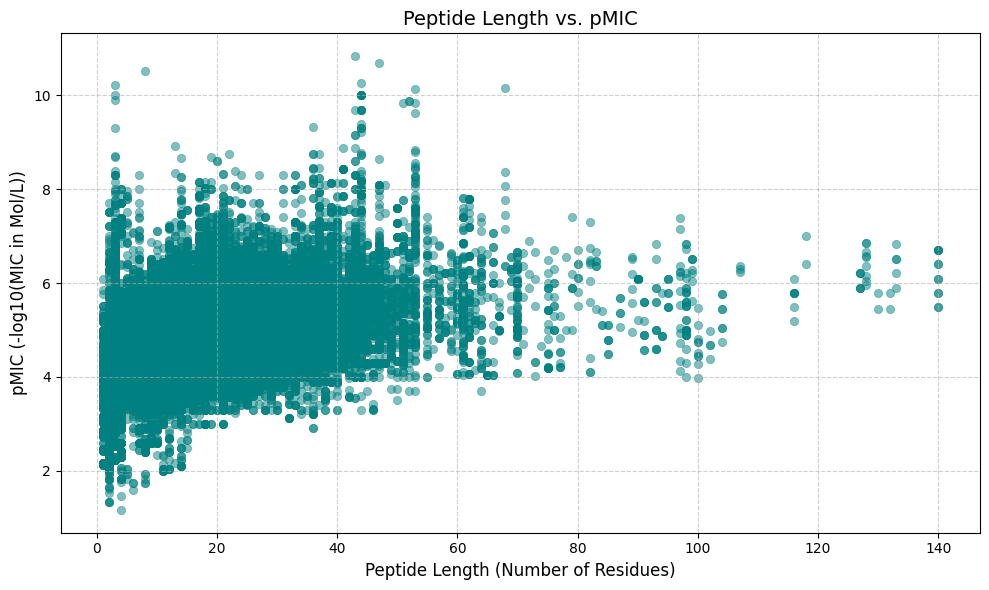

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the converted dataset
mic_df = pd.read_csv("data/processed/mic_dataset_converted.csv")

# Calculate peptide sequence lengths
mic_df['sequence_length'] = mic_df['sequence'].astype(str).str.strip().str.len()

# Create the scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=mic_df,
    x='sequence_length',
    y='pMIC',
    alpha=0.5,
    color='teal',
    edgecolor=None
)

plt.title('Peptide Length vs. pMIC', fontsize=14)
plt.xlabel('Peptide Length (Number of Residues)', fontsize=12)
plt.ylabel('pMIC (-log10(MIC in Mol/L))', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

Amino Acid Freq Calculation (AAC)

In [ ]:
import pandas as pd
from collections import Counter

# Load dataset
df = pd.read_csv(
    "data/processed/activity_measurements.csv",
    low_memory=False
)

# Select first 20 rows
df = df.head(20).copy()

# 20 standard amino acids
amino_acids = list("ACDEFGHIKLMNPQRSTVWY")


def calculate_aac(sequence):
    if pd.isna(sequence) or not str(sequence).strip():
        return {aa: None for aa in amino_acids}

    sequence = str(sequence).strip().upper()
    counts = Counter(sequence)
    total = len(sequence)

    return {
        aa: counts.get(aa, 0) / total
        for aa in amino_acids
    }


# Calculate AAC for each row
aac_df = df["sequence"].apply(calculate_aac).apply(pd.Series)

# Rename the 20 columns
aac_df.columns = [f"AAC_{aa}" for aa in aac_df.columns]

# Add AAC columns to original data
result = pd.concat([df, aac_df], axis=1)

# Display results
print(result[["peptide_id", "sequence"] +
             [f"AAC_{aa}" for aa in amino_acids]].to_string(index=False))

# Save separately
result.to_csv(
    "data/processed/first_20_with_aac.csv",
    index=False
)

 peptide_id   sequence  AAC_A  AAC_C  AAC_D  AAC_E    AAC_F  AAC_G  AAC_H    AAC_I  AAC_K    AAC_L  AAC_M  AAC_N  AAC_P  AAC_Q  AAC_R  AAC_S  AAC_T  AAC_V  AAC_W  AAC_Y
         10     LFIFFF    0.0    0.0    0.0    0.0 0.666667    0.0    0.0 0.166667    0.0 0.166667    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
         10     LFIFFF    0.0    0.0    0.0    0.0 0.666667    0.0    0.0 0.166667    0.0 0.166667    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
         10     LFIFFF    0.0    0.0    0.0    0.0 0.666667    0.0    0.0 0.166667    0.0 0.166667    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
         10     LFIFFF    0.0    0.0    0.0    0.0 0.666667    0.0    0.0 0.166667    0.0 0.166667    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0    0.0
      10000 IKQVKKLFKK    0.0    0.0    0.0    0.0 0.100000    0.0    0.0 0.100000    0.5 0.100000    0.0    0.0    0.0    0.1    0.0    0.0    0.0    0.1 

Dipeptide Concentration (DPC)

In [ ]:
import pandas as pd
from itertools import product

# Load dataset
df = pd.read_csv(
    "data/processed/activity_measurements.csv",
    low_memory=False
)

# Select first 20 rows
df = df.head(20).copy()

# 20 standard amino acids
amino_acids = "ACDEFGHIKLMNPQRSTVWY"

# Generate all 400 possible dipeptides
dipeptides = [
    aa1 + aa2
    for aa1, aa2 in product(amino_acids, repeat=2)
]


def calculate_dpc(sequence):
    # Missing or empty sequence
    if pd.isna(sequence) or not str(sequence).strip():
        return {dp: None for dp in dipeptides}

    sequence = str(sequence).strip().upper()

    # Count only valid dipeptides formed by standard amino acids
    counts = {dp: 0 for dp in dipeptides}

    for i in range(len(sequence) - 1):
        dp = sequence[i:i + 2]

        if dp in counts:
            counts[dp] += 1

    # Normalize using the number of valid dipeptides
    valid_pairs = sum(counts.values())

    if valid_pairs == 0:
        return {dp: None for dp in dipeptides}

    return {
        dp: counts[dp] / valid_pairs
        for dp in dipeptides
    }


# Calculate DPC for each row
dpc_df = df["sequence"].apply(calculate_dpc).apply(pd.Series)

# Rename columns
dpc_df.columns = [f"DPC_{dp}" for dp in dpc_df.columns]

# Add DPC features to the original data
result = pd.concat([df, dpc_df], axis=1)

# Display peptide ID, sequence and DPC features
print(
    result[
        ["peptide_id", "sequence"] +
        [f"DPC_{dp}" for dp in dipeptides]
    ].to_string(index=False)
)

# Save separately
result.to_csv(
    "data/processed/first_20_with_dpc.csv",
    index=False
)

print("\nDPC calculation completed!")
print("Dataset shape:", result.shape)
print("Number of DPC features:", len(dipeptides))

 peptide_id   sequence  DPC_AA  DPC_AC  DPC_AD  DPC_AE  DPC_AF  DPC_AG  DPC_AH  DPC_AI  DPC_AK  DPC_AL  DPC_AM  DPC_AN  DPC_AP  DPC_AQ  DPC_AR  DPC_AS  DPC_AT  DPC_AV  DPC_AW  DPC_AY  DPC_CA  DPC_CC  DPC_CD  DPC_CE  DPC_CF  DPC_CG  DPC_CH  DPC_CI  DPC_CK  DPC_CL  DPC_CM  DPC_CN  DPC_CP  DPC_CQ  DPC_CR  DPC_CS  DPC_CT  DPC_CV  DPC_CW  DPC_CY  DPC_DA  DPC_DC  DPC_DD  DPC_DE  DPC_DF  DPC_DG  DPC_DH  DPC_DI  DPC_DK  DPC_DL  DPC_DM  DPC_DN  DPC_DP  DPC_DQ  DPC_DR  DPC_DS  DPC_DT  DPC_DV  DPC_DW  DPC_DY  DPC_EA  DPC_EC  DPC_ED  DPC_EE  DPC_EF  DPC_EG  DPC_EH  DPC_EI  DPC_EK  DPC_EL  DPC_EM  DPC_EN  DPC_EP  DPC_EQ  DPC_ER  DPC_ES  DPC_ET  DPC_EV  DPC_EW  DPC_EY  DPC_FA  DPC_FC  DPC_FD  DPC_FE  DPC_FF  DPC_FG  DPC_FH  DPC_FI   DPC_FK  DPC_FL  DPC_FM  DPC_FN  DPC_FP  DPC_FQ  DPC_FR  DPC_FS  DPC_FT  DPC_FV  DPC_FW  DPC_FY  DPC_GA  DPC_GC  DPC_GD  DPC_GE  DPC_GF  DPC_GG  DPC_GH  DPC_GI  DPC_GK  DPC_GL  DPC_GM  DPC_GN  DPC_GP  DPC_GQ  DPC_GR  DPC_GS  DPC_GT  DPC_GV  DPC_GW  DPC_GY  DPC_HA  DPC_HC 

Target Species Analysis & pMIC Comparison

In [ ]:
import pandas as pd

# Load the converted dataset containing calculated pMIC values
mic_df = pd.read_csv('data/processed/mic_dataset_converted.csv')

# Group by target species and calculate statistics
target_stats = mic_df.groupby('target_species').agg(
    mean_pMIC=('pMIC', 'mean'),
    median_pMIC=('pMIC', 'median'),
    record_count=('pMIC', 'count')
).reset_index()

# Sort by record count to see the most frequently tested strains/species
target_stats_sorted = target_stats.sort_values(by='record_count', ascending=False)

print('=== Top 20 Most Frequent Target Species and Their Average pMIC ===')
display(target_stats_sorted.head(20))

=== Top 20 Most Frequent Target Species and Their Average pMIC ===


,target_species,mean_pMIC,median_pMIC,record_count
1723,Escherichia coli ATCC 25922,5.049247,5.096910,6405
3983,Staphylococcus aureus ATCC 25923,5.034970,5.096910,3632
3203,Pseudomonas aeruginosa ATCC 27853,4.991993,5.000000,3268
3989,Staphylococcus aureus ATCC 29213,5.039275,5.096910,1889
3868,Staphylococcus aureus,5.050659,5.096910,1814
1645,Escherichia coli,5.006562,5.083776,1371
56,Acinetobacter baumannii ATCC 19606,5.104706,5.096910,1310
3382,Pseudomonas aeruginosa PAO1,4.986995,5.005009,1234
3083,Pseudomonas aeruginosa,4.980738,4.973408,1155
4362,Staphylococcus epidermidis ATCC 12228,5.128204,5.204120,1092


next steps:
